# 🏠 Jakarta House Price Prediction — DL v2 (Log-Transform + Optimized)

**Upgrade dari v1:**
- Target pakai `log(price)` → distribusi lebih normal, training jauh stabil
- Epochs naik ke 100, learning rate diturunin ke 5e-4
- Arsitektur tetap: DNN + Entity Embeddings (PyTorch)

> Upload file `jakarta_house.csv` ke Colab sebelum run.


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import warnings, joblib
warnings.filterwarnings('ignore')

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | Device: {device}")


PyTorch 2.11.0+cu130 | Device: cuda


## 1. Load & Preprocessing

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])
except ImportError:
    df = pd.read_csv("jakarta_house.csv")

df = df.drop(columns=['index'])
print(f"Shape: {df.shape}")
df.head(5)


Saving jakarta_house.csv to jakarta_house (1).csv
Shape: (10000, 8)


,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


Setelah clip outlier: 9723 rows
Cities: 5 | Districts: 251


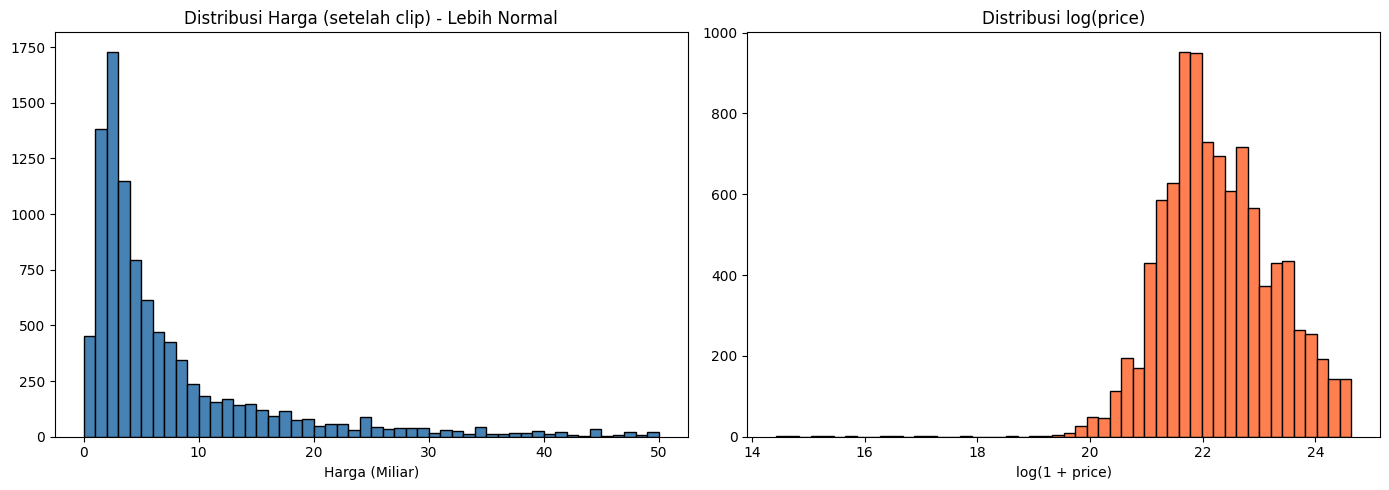

In [ ]:
num_cols = ['bed_rooms', 'bath_rooms', 'carport', 'land_area', 'building_area']
cat_cols = ['district', 'city']

for c in num_cols:
    df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])

# === FIX V3: Clip outlier harga > 50 Miliar ===
df = df[df['price'] <= 50_000_000_000].copy()
print(f"Setelah clip outlier: {df.shape[0]} rows")

# Log-transform target
df['log_price'] = np.log1p(df['price'])

le_city = LabelEncoder()
le_district = LabelEncoder()
df['city_enc'] = le_city.fit_transform(df['city'])
df['district_enc'] = le_district.fit_transform(df['district'])

n_cities = len(le_city.classes_)
n_districts = len(le_district.classes_)
print(f"Cities: {n_cities} | Districts: {n_districts}")

# Plot before vs after
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df['price'] / 1e9, bins=50, color='steelblue', edgecolor='black')
axes[0].set_title('Distribusi Harga (setelah clip) - Lebih Normal')
axes[0].set_xlabel('Harga (Miliar)')
axes[1].hist(df['log_price'], bins=50, color='coral', edgecolor='black')
axes[1].set_title('Distribusi log(price)')
axes[1].set_xlabel('log(1 + price)')
plt.tight_layout()
plt.show()

In [ ]:
feature_num_cols = ['bed_rooms', 'bath_rooms', 'carport', 'land_area', 'building_area']
X_num = df[feature_num_cols].values.astype(np.float32)
X_cat = df[['city_enc', 'district_enc']].values.astype(np.int64)
y = df['log_price'].values.astype(np.float32)  # <-- pakai log_price sekarang

X_num_train, X_num_test, X_cat_train, X_cat_test, y_train, y_test = train_test_split(
    X_num, X_cat, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_num_train = scaler.fit_transform(X_num_train)
X_num_test = scaler.transform(X_num_test)

print(f"Train: {len(y_train)} | Test: {len(y_test)}")
print(f"Target range (log): {y_train.min():.2f} - {y_train.max():.2f}")


Train: 7778 | Test: 1945
Target range (log): 14.60 - 24.64


## 2. Dataset & DataLoader

In [ ]:
class HouseDataset(Dataset):
    def __init__(self, x_num, x_cat, y):
        self.x_num = torch.tensor(x_num, dtype=torch.float32)
        self.x_cat = torch.tensor(x_cat, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    def __len__(self): return len(self.y)
    def __getitem__(self, idx):
        return self.x_num[idx], self.x_cat[idx], self.y[idx]

train_loader = DataLoader(HouseDataset(X_num_train, X_cat_train, y_train), batch_size=256, shuffle=True)
test_loader = DataLoader(HouseDataset(X_num_test, X_cat_test, y_test), batch_size=256, shuffle=False)


## 3. Model — DNN + Entity Embeddings

In [ ]:
class HousePriceNet(nn.Module):
    def __init__(self, n_num, cat_cards, emb_dims):
        super().__init__()
        self.embeddings = nn.ModuleList([nn.Embedding(c, d) for c, d in zip(cat_cards, emb_dims)])
        input_dim = n_num + sum(emb_dims)
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(64, 1)
        )
    def forward(self, x_num, x_cat):
        embs = torch.cat([e(x_cat[:, i]) for i, e in enumerate(self.embeddings)], dim=1)
        return self.net(torch.cat([x_num, embs], dim=1))

emb_dims = [min(50, n_cities // 2 + 1), min(50, n_districts // 2 + 1)]
model = HousePriceNet(len(feature_num_cols), [n_cities, n_districts], emb_dims).to(device)
print(model)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")


HousePriceNet(
  (embeddings): ModuleList(
    (0): Embedding(5, 3)
    (1): Embedding(251, 50)
  )
  (net): Sequential(
    (0): Linear(in_features=58, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.1, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parameters: 69,782


## 4. Training (100 Epochs, LR 5e-4)

In [ ]:
# === FIX V3: L1Loss + 200 epochs + patience 15 ===
criterion = nn.L1Loss()  # MAE loss, lebih robust ke outlier
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=15, factor=0.5)

EPOCHS = 200
train_losses, val_losses = [], []
best_val = float('inf')

for epoch in range(EPOCHS):
    model.train()
    t_loss = 0
    for xn, xc, yb in train_loader:
        xn, xc, yb = xn.to(device), xc.to(device), yb.to(device)
        loss = criterion(model(xn, xc), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        t_loss += loss.item() * len(yb)
    t_loss /= len(train_loader.dataset)
    train_losses.append(t_loss)

    model.eval()
    v_loss = 0
    with torch.no_grad():
        for xn, xc, yb in test_loader:
            v_loss += criterion(model(xn.to(device), xc.to(device)), yb.to(device)).item() * len(yb)
    v_loss /= len(test_loader.dataset)
    val_losses.append(v_loss)
    scheduler.step(v_loss)

    if v_loss < best_val:
        best_val = v_loss
        torch.save(model.state_dict(), 'best_model.pth')

    if (epoch+1) % 20 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS} | Train: {t_loss:.4f} | Val: {v_loss:.4f} | Best: {best_val:.4f}")

print(f"\n✅ Best Val Loss: {best_val:.4f}")

Epoch   1/200 | Train: 21.8707 | Val: 21.7499 | Best: 21.7499
Epoch  20/200 | Train: 2.4809 | Val: 2.2700 | Best: 2.2700
Epoch  40/200 | Train: 1.1550 | Val: 0.4294 | Best: 0.3964
Epoch  60/200 | Train: 1.1139 | Val: 0.3755 | Best: 0.3474
Epoch  80/200 | Train: 1.0601 | Val: 0.3546 | Best: 0.3373
Epoch 100/200 | Train: 1.0207 | Val: 0.3141 | Best: 0.3128
Epoch 120/200 | Train: 1.0047 | Val: 0.3097 | Best: 0.2939
Epoch 140/200 | Train: 0.9809 | Val: 0.3185 | Best: 0.2904
Epoch 160/200 | Train: 0.9770 | Val: 0.3004 | Best: 0.2804
Epoch 180/200 | Train: 0.9595 | Val: 0.2870 | Best: 0.2804
Epoch 200/200 | Train: 0.9570 | Val: 0.2913 | Best: 0.2802

✅ Best Val Loss: 0.2802


## 5. Evaluasi

MAE       : Rp 2,261,122,560 (2.26 Miliar)
RMSE      : Rp 5,463,000,656 (5.46 Miliar)
MAPE      : 90.3%
Median APE: 20.6%  ← ini lebih representatif!


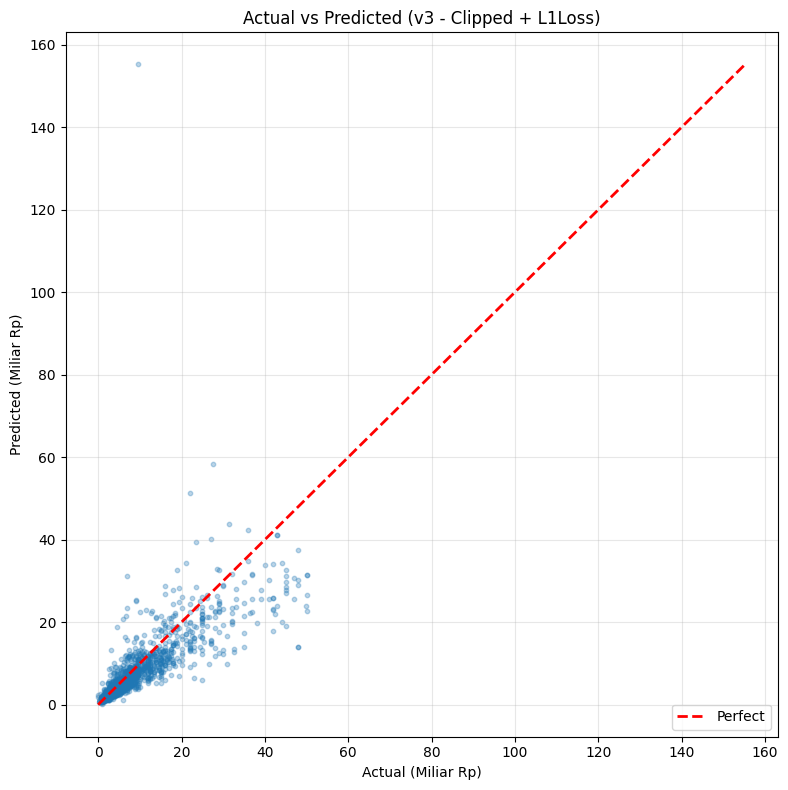

In [ ]:
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

preds_log, targets_log = [], []
with torch.no_grad():
    for xn, xc, yb in test_loader:
        p = model(xn.to(device), xc.to(device)).cpu().numpy().flatten()
        preds_log.extend(p)
        targets_log.extend(yb.numpy().flatten())

preds_log = np.array(preds_log)
targets_log = np.array(targets_log)

# Convert balik dari log ke Rupiah
preds_rupiah = np.expm1(preds_log)
targets_rupiah = np.expm1(targets_log)

mae = mean_absolute_error(targets_rupiah, preds_rupiah)
rmse = np.sqrt(mean_squared_error(targets_rupiah, preds_rupiah))
mape = np.mean(np.abs((targets_rupiah - preds_rupiah) / targets_rupiah)) * 100

# === FIX V3: Median APE (lebih jujur buat data skewed) ===
median_ape = np.median(np.abs((targets_rupiah - preds_rupiah) / targets_rupiah)) * 100

print(f"MAE       : Rp {mae:,.0f} ({mae/1e9:.2f} Miliar)")
print(f"RMSE      : Rp {rmse:,.0f} ({rmse/1e9:.2f} Miliar)")
print(f"MAPE      : {mape:.1f}%")
print(f"Median APE: {median_ape:.1f}%  ← ini lebih representatif!")

# Scatter plot
plt.figure(figsize=(8, 8))
plt.scatter(targets_rupiah/1e9, preds_rupiah/1e9, alpha=0.3, s=10)
mx = max(targets_rupiah.max(), preds_rupiah.max()) / 1e9
plt.plot([0, mx], [0, mx], 'r--', linewidth=2, label='Perfect')
plt.xlabel('Actual (Miliar Rp)')
plt.ylabel('Predicted (Miliar Rp)')
plt.title('Actual vs Predicted (v3 - Clipped + L1Loss)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


MAE       : Rp 2,261,122,560 (2.26 Miliar)
RMSE      : Rp 5,463,000,656 (5.46 Miliar)
MAPE      : 90.3%
Median APE: 20.6%  ← ini lebih representatif!


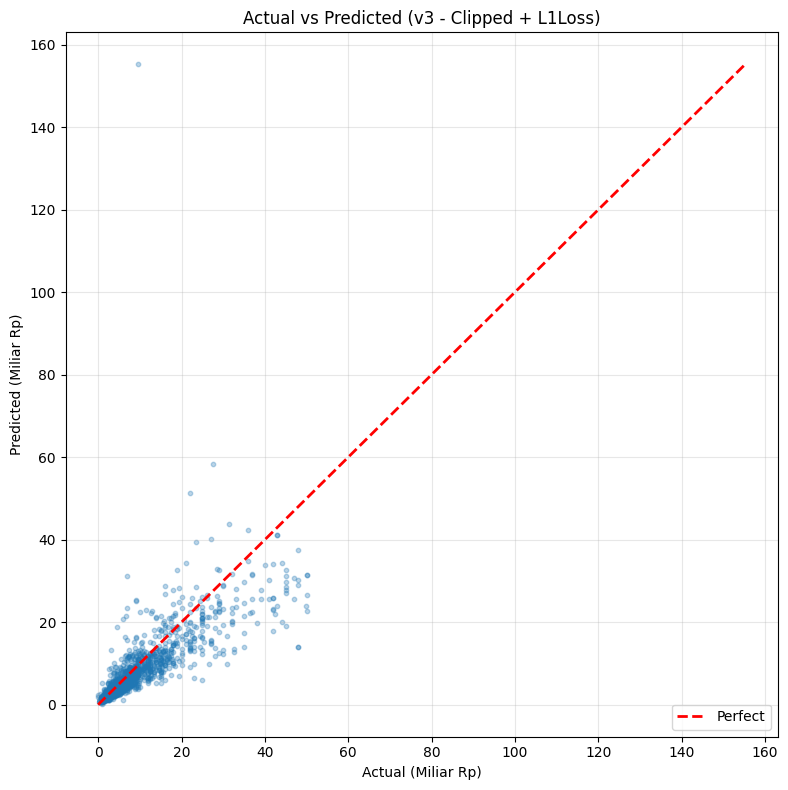

In [ ]:
model.load_state_dict(torch.load('best_model.pth'))
model.eval()

preds_log, targets_log = [], []
with torch.no_grad():
    for xn, xc, yb in test_loader:
        p = model(xn.to(device), xc.to(device)).cpu().numpy().flatten()
        preds_log.extend(p)
        targets_log.extend(yb.numpy().flatten())

preds_log = np.array(preds_log)
targets_log = np.array(targets_log)

# Convert balik dari log ke Rupiah
preds_rupiah = np.expm1(preds_log)
targets_rupiah = np.expm1(targets_log)

mae = mean_absolute_error(targets_rupiah, preds_rupiah)
rmse = np.sqrt(mean_squared_error(targets_rupiah, preds_rupiah))
mape = np.mean(np.abs((targets_rupiah - preds_rupiah) / targets_rupiah)) * 100

# === FIX V3: Median APE (lebih jujur buat data skewed) ===
median_ape = np.median(np.abs((targets_rupiah - preds_rupiah) / targets_rupiah)) * 100

print(f"MAE       : Rp {mae:,.0f} ({mae/1e9:.2f} Miliar)")
print(f"RMSE      : Rp {rmse:,.0f} ({rmse/1e9:.2f} Miliar)")
print(f"MAPE      : {mape:.1f}%")
print(f"Median APE: {median_ape:.1f}%  ← ini lebih representatif!")

# Scatter plot
plt.figure(figsize=(8, 8))
plt.scatter(targets_rupiah/1e9, preds_rupiah/1e9, alpha=0.3, s=10)
mx = max(targets_rupiah.max(), preds_rupiah.max()) / 1e9
plt.plot([0, mx], [0, mx], 'r--', linewidth=2, label='Perfect')
plt.xlabel('Actual (Miliar Rp)')
plt.ylabel('Predicted (Miliar Rp)')
plt.title('Actual vs Predicted (v3 - Clipped + L1Loss)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Save Artifacts

In [ ]:
torch.save({
    'model_state_dict': model.state_dict(),
    'n_num_features': len(feature_num_cols),
    'cat_cardinalities': [n_cities, n_districts],
    'emb_dims': emb_dims,
}, 'house_price_model_v2.pth')

joblib.dump(scaler, 'scaler.pkl')
joblib.dump(le_city, 'le_city.pkl')
joblib.dump(le_district, 'le_district.pkl')

print("✅ Saved: house_price_model_v2.pth, scaler.pkl, le_city.pkl, le_district.pkl")
print("Download semua file ini dari Colab!")


✅ Saved: house_price_model_v2.pth, scaler.pkl, le_city.pkl, le_district.pkl
Download semua file ini dari Colab!


## 7. Test Inference

In [ ]:
def predict_price(bed_rooms, bath_rooms, carport, land_area, building_area, city, district):
    model.eval()
    try: city_id = le_city.transform([city])[0]
    except: city_id = 0
    try: dist_id = le_district.transform([district])[0]
    except: dist_id = 0

    xn = scaler.transform(np.array([[bed_rooms, bath_rooms, carport, land_area, building_area]], dtype=np.float32))
    xc = np.array([[city_id, dist_id]], dtype=np.int64)

    with torch.no_grad():
        pred_log = model(torch.tensor(xn).to(device), torch.tensor(xc).to(device)).item()

    pred_rupiah = np.expm1(pred_log)  # convert balik dari log
    return pred_rupiah

tests = [
    {"bed_rooms":3,"bath_rooms":2,"carport":1,"land_area":120,"building_area":90,"city":"Jakarta Selatan","district":"Kemang"},
    {"bed_rooms":2,"bath_rooms":1,"carport":0,"land_area":60,"building_area":45,"city":"Jakarta Timur","district":"Cengkareng"},
    {"bed_rooms":5,"bath_rooms":4,"carport":2,"land_area":300,"building_area":250,"city":"Jakarta Utara","district":"Pantai Indah Kapuk"},
]

print("🔮 Prediksi Harga Rumah:\n")
for t in tests:
    p = predict_price(**t)
    print(f"📍 {t['district']}, {t['city']} | {t['bed_rooms']}KT/{t['bath_rooms']}KM | LT:{t['land_area']}m² LB:{t['building_area']}m²")
    print(f"   Estimasi: Rp {p/1e9:.2f} Miliar ({p:,.0f} Rupiah)\n")


🔮 Prediksi Harga Rumah:

📍 Kemang, Jakarta Selatan | 3KT/2KM | LT:120m² LB:90m²
   Estimasi: Rp 3.61 Miliar (3,607,637,799 Rupiah)

📍 Cengkareng, Jakarta Timur | 2KT/1KM | LT:60m² LB:45m²
   Estimasi: Rp 0.79 Miliar (785,743,918 Rupiah)

📍 Pantai Indah Kapuk, Jakarta Utara | 5KT/4KM | LT:300m² LB:250m²
   Estimasi: Rp 8.39 Miliar (8,392,201,941 Rupiah)

